In [1]:
import torch

print("="*50)
print("CUDA Available :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))
    print("GPU Count :", torch.cuda.device_count())

print("="*50)

CUDA Available : True
GPU : Tesla T4
GPU Count : 2


In [ ]:
import os
import random
import warnings
import numpy as np
import pandas as pd
import torch
import transformers
import datasets

warnings.filterwarnings("ignore")


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("="*70)
print("Mental Health Emotion Recognition")
print("="*70)

print(f"Python          : {__import__('sys').version.split()[0]}")
print(f"PyTorch         : {torch.__version__}")
print(f"Transformers    : {transformers.__version__}")
print(f"Datasets        : {datasets.__version__}")
print(f"NumPy           : {np.__version__}")
print(f"Pandas          : {pd.__version__}")

print("-"*70)

print("CUDA Available  :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU             :", torch.cuda.get_device_name(0))
    print("GPU Count       :", torch.cuda.device_count())

print("="*70)

Mental Health Emotion Recognition
Python          : 3.12.13
PyTorch         : 2.10.0+cu128
Transformers    : 5.0.0
Datasets        : 5.0.0
NumPy           : 2.0.2
Pandas          : 2.3.3
----------------------------------------------------------------------
CUDA Available  : True
GPU             : Tesla T4
GPU Count       : 2


In [ ]:


from datasets import load_dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

from torch.utils.data import DataLoader

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    hamming_loss
)

from tqdm.auto import tqdm

print("="*70)
print("All libraries imported successfully!")
print("="*70)

All libraries imported successfully!


In [ ]:

dataset = load_dataset("google-research-datasets/go_emotions")

print("="*70)
print("Dataset Loaded Successfully!")
print("="*70)

print(dataset)

print("\nTraining Samples   :", len(dataset["train"]))
print("Validation Samples:", len(dataset["validation"]))
print("Test Samples      :", len(dataset["test"]))

print("\nColumns:")
print(dataset["train"].column_names)

print("\nFeatures:")
print(dataset["train"].features)

print("\nFirst Sample:")
print(dataset["train"][0])

print("="*70)

README.md: 0.00B [00:00, ?B/s]

simplified/train-00000-of-00001.parquet:   0%|          | 0.00/2.77M [00:00<?, ?B/s]

simplified/validation-00000-of-00001.par(…):   0%|          | 0.00/350k [00:00<?, ?B/s]

simplified/test-00000-of-00001.parquet:   0%|          | 0.00/347k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

Dataset Loaded Successfully!
DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5427
    })
})

Training Samples   : 43410
Validation Samples: 5426
Test Samples      : 5427

Columns:
['text', 'labels', 'id']

Features:
{'text': Value('string'), 'labels': List(ClassLabel(names=['admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral'])), 'id': Value('string')}

First Sample:
{'text': "My favourite food is anything I didn't have to cook myself.", 'labels': [27], 'id': 'eebbqej'}


In [ ]:

import json

# Convert Hugging Face Dataset to Pandas DataFrames
train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

# Extract emotion names from the dataset
emotion_names = dataset["train"].features["labels"].feature.names

# Create mappings
label2id = {emotion: idx for idx, emotion in enumerate(emotion_names)}
id2label = {idx: emotion for idx, emotion in enumerate(emotion_names)}

NUM_LABELS = len(emotion_names)

print("=" * 70)
print("DataFrames Created Successfully!")
print("=" * 70)

print(f"Training Samples   : {len(train_df)}")
print(f"Validation Samples : {len(val_df)}")
print(f"Test Samples       : {len(test_df)}")

print("\nNumber of Emotion Classes :", NUM_LABELS)

print("\nEmotion Labels:")
for idx, emotion in enumerate(emotion_names):
    print(f"{idx:2d} -> {emotion}")

# Save label mapping
with open("label_mapping.json", "w") as f:
    json.dump(
        {
            "label2id": label2id,
            "id2label": id2label
        },
        f,
        indent=4
    )

print("\nlabel_mapping.json saved successfully!")

print("=" * 70)

DataFrames Created Successfully!
Training Samples   : 43410
Validation Samples : 5426
Test Samples       : 5427

Number of Emotion Classes : 28

Emotion Labels:
 0 -> admiration
 1 -> amusement
 2 -> anger
 3 -> annoyance
 4 -> approval
 5 -> caring
 6 -> confusion
 7 -> curiosity
 8 -> desire
 9 -> disappointment
10 -> disapproval
11 -> disgust
12 -> embarrassment
13 -> excitement
14 -> fear
15 -> gratitude
16 -> grief
17 -> joy
18 -> love
19 -> nervousness
20 -> optimism
21 -> pride
22 -> realization
23 -> relief
24 -> remorse
25 -> sadness
26 -> surprise
27 -> neutral

label_mapping.json saved successfully!


In [ ]:
import numpy as np

def create_multi_hot(label_list, num_labels=NUM_LABELS):
    multi_hot = np.zeros(num_labels, dtype=np.float32)
    multi_hot[label_list] = 1.0
    return multi_hot

# Apply to each split
train_df["multi_hot_labels"] = train_df["labels"].apply(create_multi_hot)
val_df["multi_hot_labels"] = val_df["labels"].apply(create_multi_hot)
test_df["multi_hot_labels"] = test_df["labels"].apply(create_multi_hot)

print("=" * 70)
print("Multi-Hot Encoding Completed Successfully!")
print("=" * 70)

print("Example Text:")
print(train_df.iloc[0]["text"])

print("\nOriginal Labels:")
print(train_df.iloc[0]["labels"])

print("\nMulti-Hot Vector:")
print(train_df.iloc[0]["multi_hot_labels"])

print("\nVector Length:")
print(len(train_df.iloc[0]["multi_hot_labels"]))

print("\nActive Labels:")
print(int(train_df.iloc[0]["multi_hot_labels"].sum()))

print("=" * 70)

Multi-Hot Encoding Completed Successfully!
Example Text:
My favourite food is anything I didn't have to cook myself.

Original Labels:
[27]

Multi-Hot Vector:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 1.]

Vector Length:
28

Active Labels:
1


In [ ]:

MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("=" * 70)
print("Tokenizer Loaded Successfully!")
print("=" * 70)

print("Model Name      :", MODEL_NAME)
print("Vocabulary Size :", tokenizer.vocab_size)
print("Maximum Length  :", MAX_LENGTH)

print("=" * 70)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Tokenizer Loaded Successfully!
Model Name      : distilbert-base-uncased
Vocabulary Size : 30522
Maximum Length  : 128


In [ ]:

def tokenize_dataframe(df):

    return tokenizer(
        list(df["text"]),
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,
        return_attention_mask=True
    )

print("Tokenizing Training Set...")
train_encodings = tokenize_dataframe(train_df)

print("Tokenizing Validation Set...")
val_encodings = tokenize_dataframe(val_df)

print("Tokenizing Test Set...")
test_encodings = tokenize_dataframe(test_df)

print("\n" + "=" * 70)
print("Tokenization Completed Successfully!")
print("=" * 70)

print("Training Samples   :", len(train_encodings["input_ids"]))
print("Validation Samples :", len(val_encodings["input_ids"]))
print("Test Samples       :", len(test_encodings["input_ids"]))

print("=" * 70)

Tokenizing Training Set...
Tokenizing Validation Set...
Tokenizing Test Set...

Tokenization Completed Successfully!
Training Samples   : 43410
Validation Samples : 5426
Test Samples       : 5427


In [ ]:

from torch.utils.data import Dataset

class GoEmotionsDataset(Dataset):

    def __init__(self, encodings, labels):

        self.encodings = encodings
        self.labels = labels

    def __len__(self):

        return len(self.labels)

    def __getitem__(self, idx):

        item = {
            "input_ids": torch.tensor(
                self.encodings["input_ids"][idx],
                dtype=torch.long
            ),

            "attention_mask": torch.tensor(
                self.encodings["attention_mask"][idx],
                dtype=torch.long
            ),

            "labels": torch.tensor(
                self.labels[idx],
                dtype=torch.float32
            )
        }

        return item


train_dataset = GoEmotionsDataset(
    train_encodings,
    train_df["multi_hot_labels"].tolist()
)

val_dataset = GoEmotionsDataset(
    val_encodings,
    val_df["multi_hot_labels"].tolist()
)

test_dataset = GoEmotionsDataset(
    test_encodings,
    test_df["multi_hot_labels"].tolist()
)

print("=" * 70)
print("PyTorch Dataset Created Successfully!")
print("=" * 70)

print("Training Dataset   :", len(train_dataset))
print("Validation Dataset :", len(val_dataset))
print("Test Dataset       :", len(test_dataset))

print("=" * 70)

PyTorch Dataset Created Successfully!
Training Dataset   : 43410
Validation Dataset : 5426
Test Dataset       : 5427


In [ ]:

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("=" * 70)
print("DataLoaders Created Successfully!")
print("=" * 70)

print("Batch Size          :", BATCH_SIZE)
print("Training Batches    :", len(train_loader))
print("Validation Batches  :", len(val_loader))
print("Test Batches        :", len(test_loader))

print("=" * 70)

DataLoaders Created Successfully!
Batch Size          : 16
Training Batches    : 2714
Validation Batches  : 340
Test Batches        : 340


In [ ]:

batch = next(iter(train_loader))

print("=" * 70)

print("Input IDs Shape      :", batch["input_ids"].shape)
print("Attention Mask Shape :", batch["attention_mask"].shape)
print("Labels Shape         :", batch["labels"].shape)

print("\nTensor Data Types")
print("----------------------------")
print("Input IDs      :", batch["input_ids"].dtype)
print("Attention Mask :", batch["attention_mask"].dtype)
print("Labels         :", batch["labels"].dtype)

print("\nFirst Sample Labels")
print(batch["labels"][0])

print("\nPositive Labels in First Sample :",
      int(batch["labels"][0].sum().item()))

print("=" * 70)

Input IDs Shape      : torch.Size([16, 128])
Attention Mask Shape : torch.Size([16, 128])
Labels Shape         : torch.Size([16, 28])

Tensor Data Types
----------------------------
Input IDs      : torch.int64
Attention Mask : torch.int64
Labels         : torch.float32

First Sample Labels
tensor([1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

Positive Labels in First Sample : 1


In [ ]:

from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    problem_type="multi_label_classification",
    output_hidden_states=True
)

model.to(device)

print("=" * 70)
print("DistilBERT Model Loaded Successfully!")
print("=" * 70)

print("Model Name      :", MODEL_NAME)
print("Number of Labels:", NUM_LABELS)
print("Problem Type    : multi_label_classification")

print("=" * 70)

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT Model Loaded Successfully!
Model Name      : distilbert-base-uncased
Number of Labels: 28
Problem Type    : multi_label_classification


In [ ]:

batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
labels = batch["labels"].to(device)

outputs = model(
    input_ids=input_ids,
    attention_mask=attention_mask,
    labels=labels
)

print("=" * 70)

print("Loss                :", outputs.loss.item())
print("Logits Shape        :", outputs.logits.shape)
print("Hidden States       :", len(outputs.hidden_states))
print("Last Hidden Shape   :", outputs.hidden_states[-1].shape)

print("=" * 70)

Loss                : 0.6957347393035889
Logits Shape        : torch.Size([16, 28])
Hidden States       : 7
Last Hidden Shape   : torch.Size([16, 128, 768])


In [ ]:

from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

# -----------------------------
# Hyperparameters
# -----------------------------
EPOCHS = 8
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10

# -----------------------------
# Optimizer
# -----------------------------
optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# -----------------------------
# Scheduler
# -----------------------------
total_steps = len(train_loader) * EPOCHS

warmup_steps = int(total_steps * WARMUP_RATIO)

scheduler = get_linear_schedule_with_warmup(
    optimizer=optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

print("=" * 70)
print("Training Configuration Ready!")
print("=" * 70)

print("Epochs        :", EPOCHS)
print("Learning Rate :", LEARNING_RATE)
print("Weight Decay  :", WEIGHT_DECAY)
print("Total Steps   :", total_steps)
print("Warmup Steps  :", warmup_steps)

print("=" * 70)

Training Configuration Ready!
Epochs        : 8
Learning Rate : 2e-05
Weight Decay  : 0.01
Total Steps   : 21712
Warmup Steps  : 2171


In [ ]:

label_matrix = np.stack(train_df["multi_hot_labels"].values)

positive_counts = label_matrix.sum(axis=0)
negative_counts = len(label_matrix) - positive_counts

positive_weights = torch.tensor(
    negative_counts / (positive_counts + 1e-5),
    dtype=torch.float32,
    device=device
)

print("=" * 70)
print("Positive Class Weights Computed Successfully!")
print("=" * 70)

print("Shape :", positive_weights.shape)

print("\nFirst 10 Weights:")
print(positive_weights[:10])

print("=" * 70)

Positive Class Weights Computed Successfully!
Shape : torch.Size([28])

First 10 Weights:
tensor([ 9.5109, 17.6469, 26.7026, 16.5749, 13.7703, 38.9356, 30.7325, 18.8129,
        66.7223, 33.2080], device='cuda:0')


In [ ]:

criterion = torch.nn.BCEWithLogitsLoss(
    pos_weight=positive_weights
)

print("=" * 70)
print("Weighted BCEWithLogitsLoss Initialized Successfully!")
print("=" * 70)

print("Loss Function :", criterion)

print("=" * 70)

Weighted BCEWithLogitsLoss Initialized Successfully!
Loss Function : BCEWithLogitsLoss()


In [ ]:

from tqdm.auto import tqdm

def train_one_epoch(
    model,
    dataloader,
    optimizer,
    scheduler,
    criterion,
    device
):

    model.train()

    total_loss = 0.0

    progress_bar = tqdm(
        dataloader,
        desc="Training",
        leave=False
    )

    for batch in progress_bar:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        logits = outputs.logits

        loss = criterion(
            logits,
            labels
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    average_loss = total_loss / len(dataloader)

    return average_loss


print("=" * 70)
print("Training Function Ready!")
print("=" * 70)

Training Function Ready!


In [ ]:

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    hamming_loss,
    accuracy_score
)

@torch.no_grad()
def validate(
    model,
    dataloader,
    criterion,
    device,
    threshold=0.5
):

    model.eval()

    total_loss = 0.0

    all_labels = []
    all_predictions = []

    progress_bar = tqdm(
        dataloader,
        desc="Validation",
        leave=False
    )

    for batch in progress_bar:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        logits = outputs.logits

        loss = criterion(
            logits,
            labels
        )

        total_loss += loss.item()

        probabilities = torch.sigmoid(logits)

        predictions = (
            probabilities >= threshold
        ).float()

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

    average_loss = total_loss / len(dataloader)

    micro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="micro",
        zero_division=0
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    precision = precision_score(
        all_labels,
        all_predictions,
        average="micro",
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        average="micro",
        zero_division=0
    )

    hamming = hamming_loss(
        all_labels,
        all_predictions
    )

    subset_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    return (
        average_loss,
        micro_f1,
        macro_f1,
        precision,
        recall,
        hamming,
        subset_accuracy
    )


print("=" * 70)
print("Validation Function Ready!")
print("=" * 70)

Validation Function Ready!


In [ ]:

class EarlyStopping:

    def __init__(self, patience=2):

        self.patience = patience
        self.counter = 0

        self.best_score = -float("inf")

        self.early_stop = False

    def __call__(self, score):

        if score > self.best_score:

            self.best_score = score
            self.counter = 0

            return True

        else:

            self.counter += 1

            print(
                f"EarlyStopping Counter: {self.counter}/{self.patience}"
            )

            if self.counter >= self.patience:

                self.early_stop = True

            return False


early_stopping = EarlyStopping(
    patience=2
)

print("=" * 70)
print("Early Stopping Ready!")
print("=" * 70)
print("Monitoring Metric : Micro-F1")
print("Patience          :", early_stopping.patience)
print("=" * 70)

Early Stopping Ready!
Monitoring Metric : Micro-F1
Patience          : 2


In [ ]:

import os
import json


SAVE_DIR = "/kaggle/working/best_distilbert_model"

os.makedirs(SAVE_DIR, exist_ok=True)


history = {
    "train_loss": [],
    "val_loss": [],
    "micro_f1": [],
    "macro_f1": [],
    "precision": [],
    "recall": [],
    "hamming_loss": [],
    "subset_accuracy": []
}


for epoch in range(EPOCHS):

    print("\n" + "="*70)
    print(f"Epoch {epoch+1}/{EPOCHS}")
    print("="*70)

    train_loss = train_one_epoch(
        model=model,
        dataloader=train_loader,
        optimizer=optimizer,
        scheduler=scheduler,
        criterion=criterion,
        device=device
    )

    (
        val_loss,
        micro_f1,
        macro_f1,
        precision,
        recall,
        hamming,
        subset_accuracy
    ) = validate(
        model=model,
        dataloader=val_loader,
        criterion=criterion,
        device=device,
        threshold=0.5
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["micro_f1"].append(micro_f1)
    history["macro_f1"].append(macro_f1)
    history["precision"].append(precision)
    history["recall"].append(recall)
    history["hamming_loss"].append(hamming)
    history["subset_accuracy"].append(subset_accuracy)

    print(f"\nTraining Loss     : {train_loss:.4f}")
    print(f"Validation Loss   : {val_loss:.4f}")
    print(f"Micro F1          : {micro_f1:.4f}")
    print(f"Macro F1          : {macro_f1:.4f}")
    print(f"Precision         : {precision:.4f}")
    print(f"Recall            : {recall:.4f}")
    print(f"Hamming Loss      : {hamming:.4f}")
    print(f"Subset Accuracy   : {subset_accuracy:.4f}")

    improved = early_stopping(micro_f1)

    if improved:

        print("\n✅ New Best Model Found!")

        model.save_pretrained(SAVE_DIR)
        tokenizer.save_pretrained(SAVE_DIR)

        with open(
            os.path.join(SAVE_DIR, "training_history.json"),
            "w"
        ) as f:

            json.dump(history, f, indent=4)

        print("✅ Model Saved")
        print("✅ Tokenizer Saved")
        print("✅ Training History Saved")

    if early_stopping.early_stop:

        print("\n🛑 Early stopping triggered!")
        break

print("\n" + "="*70)
print("Training Completed Successfully!")
print("="*70)


Epoch 1/8


Training:   0%|          | 0/2714 [00:00<?, ?it/s]

Validation:   0%|          | 0/340 [00:00<?, ?it/s]


Training Loss     : 1.0258
Validation Loss   : 0.7796
Micro F1          : 0.3737
Macro F1          : 0.3375
Precision         : 0.2421
Recall            : 0.8187
Hamming Loss      : 0.1152
Subset Accuracy   : 0.0568

✅ New Best Model Found!


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Model Saved
✅ Tokenizer Saved
✅ Training History Saved

Epoch 2/8


... (32 outputs left out)

Validation:   0%|          | 0/340 [00:00<?, ?it/s]


Training Loss     : 0.1894
Validation Loss   : 1.3028
Micro F1          : 0.5226
Macro F1          : 0.4689
Precision         : 0.4057
Recall            : 0.7343
Hamming Loss      : 0.0563
Subset Accuracy   : 0.2545

✅ New Best Model Found!


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Model Saved
✅ Tokenizer Saved
✅ Training History Saved

Training Completed Successfully!


In [ ]:

from transformers import AutoModelForSequenceClassification

best_model = AutoModelForSequenceClassification.from_pretrained(SAVE_DIR)
best_model.to(device)
best_model.eval()

print("=" * 70)
print("Loaded Best Saved Model")
print("=" * 70)

(
    test_loss,
    test_micro_f1,
    test_macro_f1,
    test_precision,
    test_recall,
    test_hamming,
    test_subset_accuracy
) = validate(
    model=best_model,
    dataloader=test_loader,
    criterion=criterion,
    device=device,
    threshold=0.5
)

print("\n" + "=" * 70)
print("TEST SET RESULTS")
print("=" * 70)

print(f"Test Loss         : {test_loss:.4f}")
print(f"Micro F1          : {test_micro_f1:.4f}")
print(f"Macro F1          : {test_macro_f1:.4f}")
print(f"Precision         : {test_precision:.4f}")
print(f"Recall            : {test_recall:.4f}")
print(f"Hamming Loss      : {test_hamming:.4f}")
print(f"Subset Accuracy   : {test_subset_accuracy:.4f}")

print("=" * 70)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loaded Best Saved Model


Validation:   0%|          | 0/340 [00:00<?, ?it/s]


TEST SET RESULTS
Test Loss         : 1.1780
Micro F1          : 0.5180
Macro F1          : 0.4629
Precision         : 0.4007
Recall            : 0.7325
Hamming Loss      : 0.0568
Subset Accuracy   : 0.2423


In [ ]:

import numpy as np

thresholds = np.arange(0.10, 0.95, 0.05)

results = []

print("=" * 70)
print("Searching Best Threshold...")
print("=" * 70)

best_threshold = 0.5
best_micro_f1 = 0

for threshold in thresholds:

    (
        val_loss,
        micro_f1,
        macro_f1,
        precision,
        recall,
        hamming,
        subset_accuracy
    ) = validate(
        model=best_model,
        dataloader=val_loader,
        criterion=criterion,
        device=device,
        threshold=threshold
    )

    results.append({
        "threshold": threshold,
        "micro_f1": micro_f1,
        "macro_f1": macro_f1,
        "precision": precision,
        "recall": recall
    })

    print(
        f"Threshold: {threshold:.2f} | "
        f"Micro-F1: {micro_f1:.4f}"
    )

    if micro_f1 > best_micro_f1:
        best_micro_f1 = micro_f1
        best_threshold = threshold

print("\n" + "=" * 70)
print(f"Best Threshold : {best_threshold:.2f}")
print(f"Best Micro-F1  : {best_micro_f1:.4f}")
print("=" * 70)

Searching Best Threshold...


Validation:   0%|          | 0/340 [00:00<?, ?it/s]

Threshold: 0.10 | Micro-F1: 0.4010


Validation:   0%|          | 0/340 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d8a0599f7e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d8a0599f7e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

Threshold: 0.15 | Micro-F1: 0.4327


... (28 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d8a0599f7e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d8a0599f7e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

Threshold: 0.85 | Micro-F1: 0.5546


Validation:   0%|          | 0/340 [00:00<?, ?it/s]

Threshold: 0.90 | Micro-F1: 0.5491

Best Threshold : 0.85
Best Micro-F1  : 0.5546


In [23]:
# ==========================================================
# Final Test Evaluation using Best Threshold
# ==========================================================

print("=" * 70)
print(f"Evaluating Test Set with Best Threshold = {best_threshold:.2f}")
print("=" * 70)

(
    test_loss,
    test_micro_f1,
    test_macro_f1,
    test_precision,
    test_recall,
    test_hamming,
    test_subset_accuracy
) = validate(
    model=best_model,
    dataloader=test_loader,
    criterion=criterion,
    device=device,
    threshold=best_threshold
)

print("\n" + "=" * 70)
print("FINAL TEST RESULTS")
print("=" * 70)

print(f"Best Threshold   : {best_threshold:.2f}")
print(f"Test Loss        : {test_loss:.4f}")
print(f"Micro F1         : {test_micro_f1:.4f}")
print(f"Macro F1         : {test_macro_f1:.4f}")
print(f"Precision        : {test_precision:.4f}")
print(f"Recall           : {test_recall:.4f}")
print(f"Hamming Loss     : {test_hamming:.4f}")
print(f"Subset Accuracy  : {test_subset_accuracy:.4f}")

print("=" * 70)

Evaluating Test Set with Best Threshold = 0.85


Validation:   0%|          | 0/340 [00:00<?, ?it/s]


FINAL TEST RESULTS
Best Threshold   : 0.85
Test Loss        : 1.1780
Micro F1         : 0.5473
Macro F1         : 0.5042
Precision        : 0.5267
Recall           : 0.5696
Hamming Loss     : 0.0392
Subset Accuracy  : 0.3788


In [24]:
import shutil

# Create a ZIP archive of the saved model directory
shutil.make_archive(
    "/kaggle/working/best_distilbert_model",
    "zip",
    "/kaggle/working/best_distilbert_model"
)

print("Model zipped successfully!")
print("/kaggle/working/best_distilbert_model.zip")

Model zipped successfully!
/kaggle/working/best_distilbert_model.zip


In [ ]:

from sklearn.metrics import classification_report
import numpy as np
import pandas as pd
import torch

best_model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():

    for batch in test_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].cpu().numpy()

        outputs = best_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        probabilities = torch.sigmoid(outputs.logits).cpu().numpy()

        predictions = (probabilities >= best_threshold).astype(int)

        all_labels.append(labels)
        all_predictions.append(predictions)

all_labels = np.vstack(all_labels)
all_predictions = np.vstack(all_predictions)

emotion_names = [id2label[i] for i in range(len(id2label))]

report = classification_report(
    all_labels,
    all_predictions,
    target_names=emotion_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("=" * 80)
print("Classification Report")
print("=" * 80)

display(report_df.round(4))

Classification Report


,precision,recall,f1-score,support
admiration,0.6642,0.7262,0.6938,504.0
amusement,0.7524,0.9091,0.8233,264.0
anger,0.4708,0.6111,0.5319,198.0
annoyance,0.3364,0.4562,0.3873,320.0
approval,0.3907,0.4074,0.3989,351.0
caring,0.3508,0.4963,0.4110,135.0
confusion,0.2887,0.6340,0.3967,153.0
curiosity,0.4671,0.7500,0.5757,284.0
desire,0.5476,0.5542,0.5509,83.0
disappointment,0.2554,0.3113,0.2806,151.0


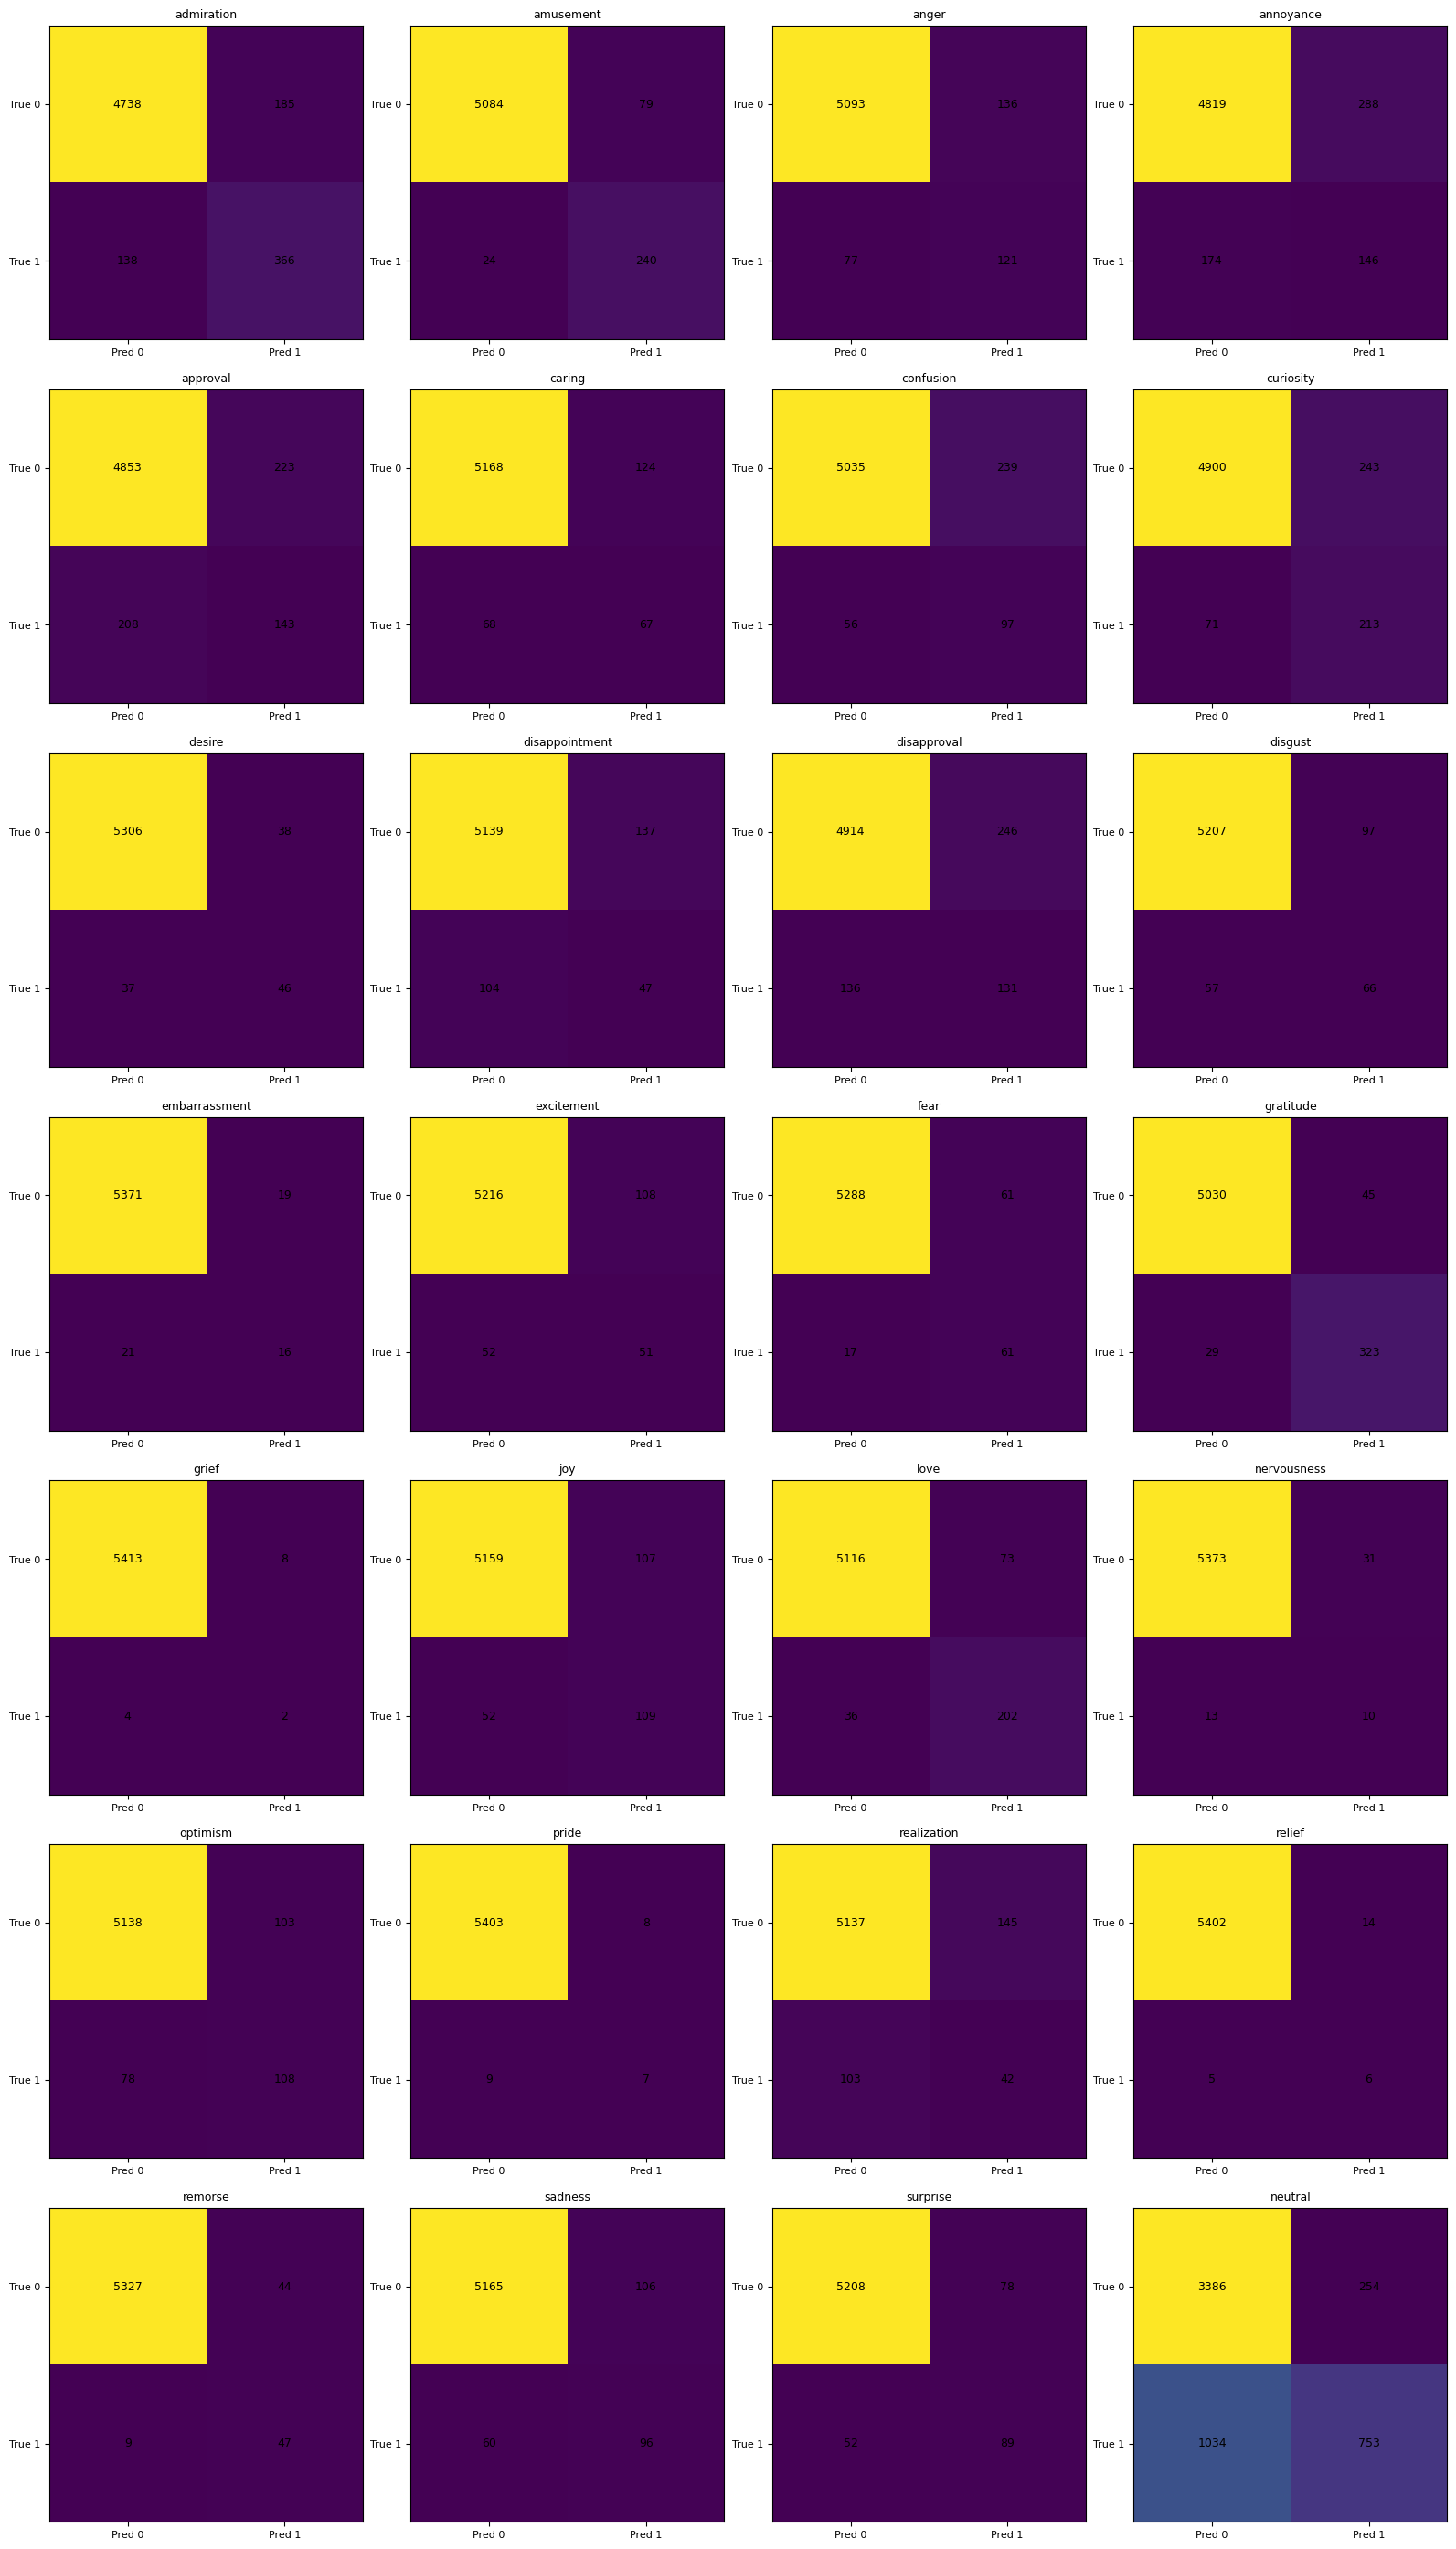

In [ ]:
from sklearn.metrics import multilabel_confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

# Generate confusion matrices
mcm = multilabel_confusion_matrix(all_labels, all_predictions)

# Number of emotions
num_classes = len(emotion_names)

# Create subplots (4 columns)
cols = 4
rows = int(np.ceil(num_classes / cols))

fig, axes = plt.subplots(rows, cols, figsize=(16, rows * 4))
axes = axes.flatten()

for i, cm in enumerate(mcm):
    ax = axes[i]

    im = ax.imshow(cm)

    ax.set_title(emotion_names[i], fontsize=9)

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Pred 0", "Pred 1"], fontsize=8)

    ax.set_yticks([0, 1])
    ax.set_yticklabels(["True 0", "True 1"], fontsize=8)

    for r in range(2):
        for c in range(2):
            ax.text(
                c,
                r,
                str(cm[r, c]),
                ha="center",
                va="center",
                fontsize=9
            )

# Remove unused axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

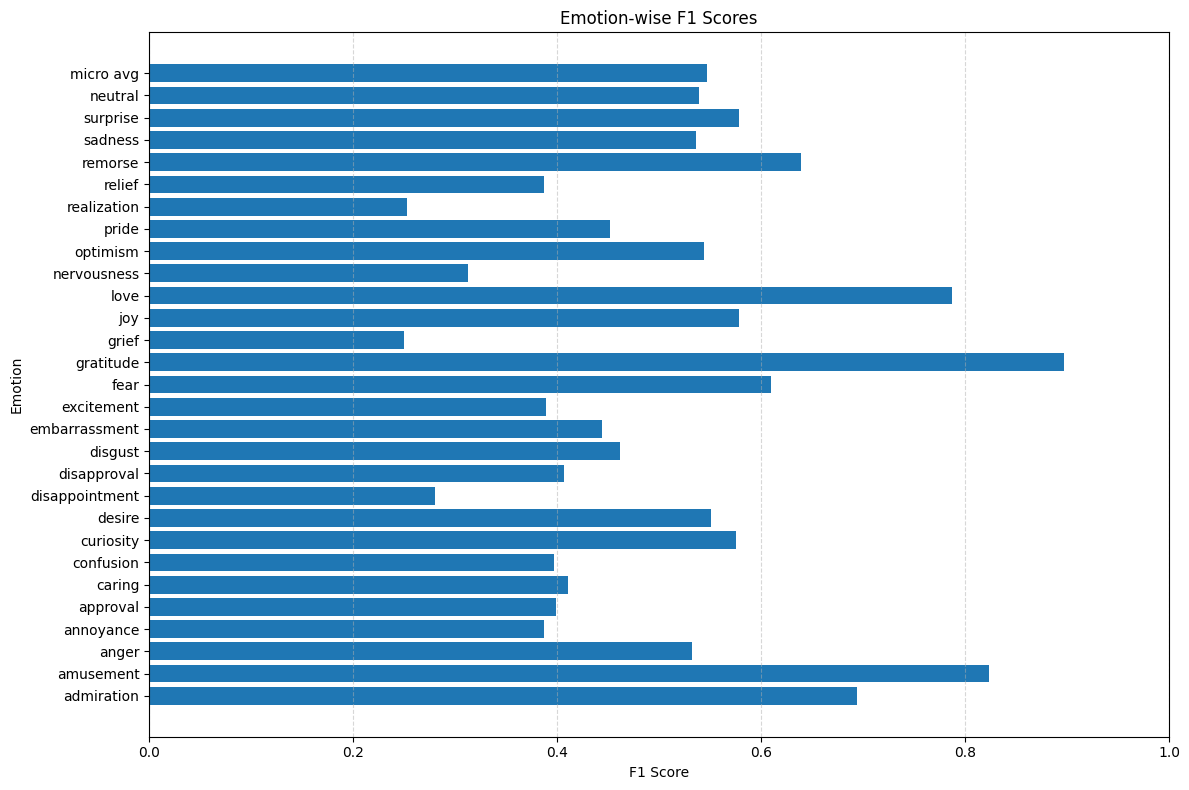

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

# Remove summary rows
emotion_report = report_df.iloc[:-3]

plt.figure(figsize=(12,8))

plt.barh(
    emotion_report.index,
    emotion_report["f1-score"]
)

plt.xlabel("F1 Score")
plt.ylabel("Emotion")
plt.title("Emotion-wise F1 Scores")

plt.xlim(0,1)

plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

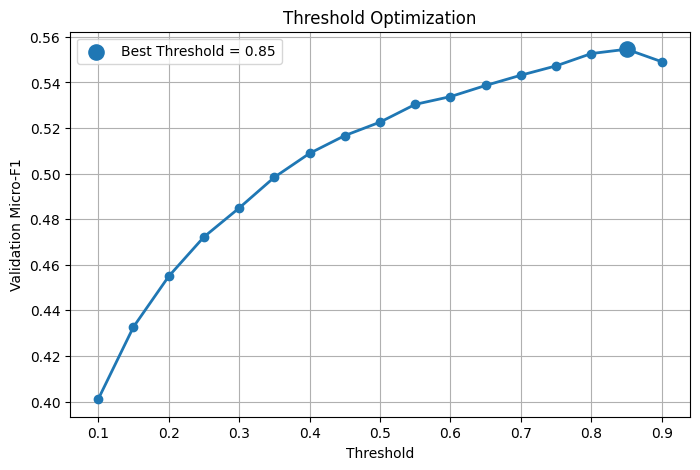

In [ ]:

import matplotlib.pyplot as plt

# Thresholds searched
thresholds = [
    0.10,0.15,0.20,0.25,0.30,
    0.35,0.40,0.45,0.50,0.55,
    0.60,0.65,0.70,0.75,0.80,
    0.85,0.90
]

# Corresponding Micro-F1 scores
threshold_scores = [
    0.4010,
    0.4327,
    0.4549,
    0.4722,
    0.4849,
    0.4984,
    0.5089,
    0.5167,
    0.5226,
    0.5304,
    0.5338,
    0.5387,
    0.5432,
    0.5473,
    0.5527,
    0.5546,
    0.5491
]

plt.figure(figsize=(8,5))

plt.plot(
    thresholds,
    threshold_scores,
    marker="o",
    linewidth=2
)

plt.scatter(
    0.85,
    0.5546,
    s=120,
    label="Best Threshold = 0.85"
)

plt.xlabel("Threshold")
plt.ylabel("Validation Micro-F1")
plt.title("Threshold Optimization")
plt.grid(True)
plt.legend()

plt.show()

In [ ]:

import os
import json
import pandas as pd

SAVE_RESULTS = "/kaggle/working/results"

os.makedirs(SAVE_RESULTS, exist_ok=True)


metrics = {
    "Best Threshold": best_threshold,
    "Test Loss": test_loss,
    "Micro F1": test_micro_f1,
    "Macro F1": test_macro_f1,
    "Precision": test_precision,
    "Recall": test_recall,
    "Hamming Loss": test_hamming,
    "Subset Accuracy": test_subset_accuracy
}

metrics_df = pd.DataFrame(
    metrics.items(),
    columns=["Metric", "Value"]
)

metrics_df.to_csv(
    os.path.join(SAVE_RESULTS, "evaluation_metrics.csv"),
    index=False
)


report_df.to_csv(
    os.path.join(SAVE_RESULTS, "classification_report.csv")
)


with open(
    os.path.join(SAVE_RESULTS, "evaluation_metrics.json"),
    "w"
) as f:
    json.dump(metrics, f, indent=4)

print("=" * 70)
print("All evaluation results saved successfully!")
print("=" * 70)
print(f"Location : {SAVE_RESULTS}")

print("\nFiles Saved:")

for file in os.listdir(SAVE_RESULTS):
    print("✓", file)

All evaluation results saved successfully!
Location : /kaggle/working/results

Files Saved:
✓ evaluation_metrics.csv
✓ classification_report.csv
✓ evaluation_metrics.json


In [ ]:

import os

MODEL_DIR = "/kaggle/working/final_distilbert_model"

os.makedirs(MODEL_DIR, exist_ok=True)

# Save model
best_model.save_pretrained(MODEL_DIR)

# Save tokenizer
tokenizer.save_pretrained(MODEL_DIR)

# Save label mappings
import json

with open(os.path.join(MODEL_DIR, "id2label.json"), "w") as f:
    json.dump(id2label, f, indent=4)

with open(os.path.join(MODEL_DIR, "label2id.json"), "w") as f:
    json.dump(label2id, f, indent=4)

print("=" * 70)
print("Final DistilBERT model saved successfully!")
print("=" * 70)

print(f"Location : {MODEL_DIR}")

print("\nSaved Files:")
for file in sorted(os.listdir(MODEL_DIR)):
    print("✓", file)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Final DistilBERT model saved successfully!
Location : /kaggle/working/final_distilbert_model

Saved Files:
✓ config.json
✓ id2label.json
✓ label2id.json
✓ model.safetensors
✓ tokenizer.json
✓ tokenizer_config.json


In [ ]:

import shutil
import os

MODEL_DIR = "/kaggle/working/final_distilbert_model"

zip_path = shutil.make_archive(
    "/kaggle/working/final_distilbert_model",
    "zip",
    MODEL_DIR
)

print("=" * 70)
print("ZIP Archive Created Successfully!")
print("=" * 70)

print(f"ZIP File : {zip_path}")

ZIP Archive Created Successfully!
ZIP File : /kaggle/working/final_distilbert_model.zip


In [34]:
from transformers import AutoConfig

MODEL_DIR = "/kaggle/working/final_distilbert_model"

loaded_model.config.id2label = id2label
loaded_model.config.label2id = label2id

loaded_model.save_pretrained(MODEL_DIR)

print("Label names updated successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Label names updated successfully!


In [ ]:

from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

MODEL_DIR = "/kaggle/working/final_distilbert_model"

print("=" * 70)
print("Loading Saved Model...")
print("=" * 70)

# Load tokenizer
loaded_tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR)

# Load model
loaded_model = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR)

loaded_model.to(device)
loaded_model.eval()

print("✓ Model Loaded Successfully")
print("✓ Tokenizer Loaded Successfully")

print("\nModel Configuration")
print("-" * 50)

print("Model Name      :", loaded_model.config._name_or_path)
print("Number of Labels:", loaded_model.config.num_labels)

print("\nSaved Labels")

for i in range(loaded_model.config.num_labels):
    print(f"{i:2d} : {loaded_model.config.id2label[i]}")

print("\n" + "=" * 70)
print("Verification Completed Successfully!")
print("=" * 70)

Loading Saved Model...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

✓ Model Loaded Successfully
✓ Tokenizer Loaded Successfully

Model Configuration
--------------------------------------------------
Model Name      : /kaggle/working/final_distilbert_model
Number of Labels: 28

Saved Labels
 0 : admiration
 1 : amusement
 2 : anger
 3 : annoyance
 4 : approval
 5 : caring
 6 : confusion
 7 : curiosity
 8 : desire
 9 : disappointment
10 : disapproval
11 : disgust
12 : embarrassment
13 : excitement
14 : fear
15 : gratitude
16 : grief
17 : joy
18 : love
19 : nervousness
20 : optimism
21 : pride
22 : realization
23 : relief
24 : remorse
25 : sadness
26 : surprise
27 : neutral

Verification Completed Successfully!


In [36]:
import os

print(os.path.getsize("/kaggle/working/final_distilbert_model.zip") / (1024*1024), "MB")
print(os.path.getsize("/kaggle/working/best_distilbert_model.zip") / (1024*1024), "MB")

235.82149505615234 MB
235.8216609954834 MB
